In [3]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent

DATASET_PATH = PROJECT_PATH / "dataset" / "validation"

(DATASET_PATH / "tomato_leaf").mkdir(
    parents=True, exist_ok=True
)

(DATASET_PATH / "not_tomato_leaf").mkdir(
    parents=True, exist_ok=True
)

print("Validation folders created!")
print(DATASET_PATH)

Validation folders created!
c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\dataset\validation


In [6]:
print("Path exists:", DATASET_PATH.exists())
print("Folders:", list(DATASET_PATH.iterdir()))

Path exists: True
Folders: [WindowsPath('c:/Users/mayak/OneDrive/Desktop/AgriVision-AI/dataset/validation/not_tomato_leaf'), WindowsPath('c:/Users/mayak/OneDrive/Desktop/AgriVision-AI/dataset/validation/tomato_leaf')]


In [4]:
for class_folder in DATASET_PATH.iterdir():

    if class_folder.is_dir():

        images = [
            p for p in class_folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(class_folder.name, ":", len(images))

not_tomato_leaf : 0
tomato_leaf : 0


In [7]:
from pathlib import Path
import shutil
import random

PROJECT_PATH = Path.cwd().parent

RAW_PATH = PROJECT_PATH / "dataset" / "raw"
VALIDATION_PATH = PROJECT_PATH / "dataset" / "validation"

TOMATO_PATH = VALIDATION_PATH / "tomato_leaf"
TOMATO_PATH.mkdir(parents=True, exist_ok=True)

random.seed(42)

image_extensions = [".jpg", ".jpeg", ".png"]

count = 0

for class_folder in RAW_PATH.iterdir():

    if class_folder.is_dir():

        images = [
            p for p in class_folder.rglob("*")
            if p.suffix.lower() in image_extensions
        ]

        selected_images = random.sample(
            images,
            min(50, len(images))
        )

        for image in selected_images:

            target = TOMATO_PATH / f"{count}_{image.name}"

            shutil.copy2(image, target)
            count += 1

print("Tomato leaf images copied:", count)

Tomato leaf images copied: 500


In [8]:
for class_folder in DATASET_PATH.iterdir():

    if class_folder.is_dir():

        images = [
            p for p in class_folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(class_folder.name, ":", len(images))

not_tomato_leaf : 0
tomato_leaf : 500


In [7]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent

DATASET_PATH = PROJECT_PATH / "dataset"

print("Dataset exists:", DATASET_PATH.exists())

for item in DATASET_PATH.iterdir():
    print(item.name)

Dataset exists: True
raw
README.md
validation


In [8]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent

VALIDATION_PATH = PROJECT_PATH / "dataset" / "validation"

for item in VALIDATION_PATH.iterdir():
    print(item.name)

not_tomato_leaf
tomato_leaf


In [9]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent

search_path = PROJECT_PATH

for folder in search_path.rglob("Pepper__bell___Bacterial_spot"):
    print("Found at:", folder)
    

Found at: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\dataset\validation\not_tomato_leaf\Pepper__bell___Bacterial_spot


In [10]:
from pathlib import Path
import random
import shutil

PROJECT_PATH = Path.cwd().parent

SOURCE_PATH = (
    PROJECT_PATH / "dataset" / "validation" / "not_tomato_leaf"
)

TARGET_PATH = SOURCE_PATH

random.seed(42)

extensions = [".jpg", ".jpeg", ".png"]

count = 0

for class_folder in SOURCE_PATH.iterdir():

    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.iterdir()
        if p.suffix.lower() in extensions
    ]

    selected = random.sample(images, min(20, len(images)))

    for image in selected:
        destination = TARGET_PATH / f"negative_{count}{image.suffix.lower()}"
        shutil.copy2(image, destination)
        count += 1

    print(class_folder.name, ":", len(selected))

print("Total images copied:", count)

Pepper__bell___Bacterial_spot : 5
Pepper__bell___healthy : 20
Potato___Early_blight : 20
Potato___healthy : 20
Potato___Late_blight : 20
Total images copied: 85


In [11]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent

NEGATIVE_PATH = (
    PROJECT_PATH / "dataset" / "validation" / "not_tomato_leaf"
)

extensions = [".jpg", ".jpeg", ".png"]

images = [
    p for p in NEGATIVE_PATH.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total negative images:", len(images))

Total negative images: 85


In [12]:
POSITIVE_PATH = (
    PROJECT_PATH / "dataset" / "validation" / "tomato_leaf"
)

tomato_images = [
    p for p in POSITIVE_PATH.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total tomato images:", len(tomato_images))

Total tomato images: 500


In [13]:
from pathlib import Path
import random
import shutil

PROJECT_PATH = Path.cwd().parent

POSITIVE_PATH = PROJECT_PATH / "dataset" / "validation" / "tomato_leaf"
NEGATIVE_PATH = PROJECT_PATH / "dataset" / "validation" / "not_tomato_leaf"

BALANCED_PATH = PROJECT_PATH / "dataset" / "binary_dataset"

extensions = [".jpg", ".jpeg", ".png"]

random.seed(42)

# Get images
positive_images = [
    p for p in POSITIVE_PATH.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

negative_images = [
    p for p in NEGATIVE_PATH.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

# Select equal number of images
sample_count = min(len(positive_images), len(negative_images))

selected_positive = random.sample(positive_images, sample_count)
selected_negative = random.sample(negative_images, sample_count)

# Create folders
positive_target = BALANCED_PATH / "tomato_leaf"
negative_target = BALANCED_PATH / "not_tomato_leaf"

positive_target.mkdir(parents=True, exist_ok=True)
negative_target.mkdir(parents=True, exist_ok=True)

# Copy tomato images
for i, image in enumerate(selected_positive):
    shutil.copy2(image, positive_target / f"tomato_{i}{image.suffix.lower()}")

# Copy non-tomato images
for i, image in enumerate(selected_negative):
    shutil.copy2(image, negative_target / f"negative_{i}{image.suffix.lower()}")

print("Tomato images:", len(selected_positive))
print("Non-tomato images:", len(selected_negative))
print("Total images:", sample_count * 2)

Tomato images: 85
Non-tomato images: 85
Total images: 170


In [14]:
from pathlib import Path
import tensorflow as tf

PROJECT_PATH = Path.cwd().parent

DATASET_PATH = PROJECT_PATH / "dataset" / "binary_dataset"

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 16
SEED = 42

print("Dataset exists:", DATASET_PATH.exists())

Dataset exists: True


In [15]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 170 files belonging to 2 classes.
Using 119 files for training.


In [16]:
temp_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_dataset.class_names

print("Class names:", class_names)

Found 170 files belonging to 2 classes.
Using 51 files for validation.
Class names: ['not_tomato_leaf', 'tomato_leaf']


In [17]:
total_batches = int(
    tf.data.experimental.cardinality(temp_dataset).numpy()
)

val_batches = total_batches // 2

validation_dataset = temp_dataset.take(val_batches)
test_dataset = temp_dataset.skip(val_batches)

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

print("Training batches:", len(train_dataset))
print("Validation batches:", len(validation_dataset))
print("Testing batches:", len(test_dataset))

Training batches: 8
Validation batches: 2
Testing batches: 2


In [18]:
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Sample labels:", labels[:5].numpy())

Image shape: (16, 160, 160, 3)
Label shape: (16, 1)
Sample labels: [[0.]
 [0.]
 [0.]
 [1.]
 [0.]]


In [19]:

import tensorflow as tf

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(160, 160, 3)),

    # Normalize pixel values
    tf.keras.layers.Rescaling(1./255),

    # First Convolution Block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Second Convolution Block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Third Convolution Block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Classification layers
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dropout(0.3),

    # Binary output
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [21]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.5210 - loss: 0.6836 - val_accuracy: 0.3750 - val_loss: 0.7762
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step - accuracy: 0.5546 - loss: 0.6920 - val_accuracy: 0.3125 - val_loss: 0.7146
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 225ms/step - accuracy: 0.5294 - loss: 0.6926 - val_accuracy: 0.4062 - val_loss: 0.7111
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 227ms/step - accuracy: 0.5462 - loss: 0.6826 - val_accuracy: 0.3750 - val_loss: 0.7270
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 196ms/step - accuracy: 0.5462 - loss: 0.6783 - val_accuracy: 0.3438 - val_loss: 0.7460
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 231ms/step - accuracy: 0.5462 - loss: 0.6713 - val_accuracy: 0.4062 - val_loss: 0.7307


In [22]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(images, verbose=0)

    predicted_labels = (predictions >= 0.5).astype(int).flatten()

    y_true.extend(labels.numpy().flatten().astype(int))
    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

                 precision    recall  f1-score   support

not_tomato_leaf       0.47      1.00      0.64         9
    tomato_leaf       0.00      0.00      0.00        10

       accuracy                           0.47        19
      macro avg       0.24      0.50      0.32        19
   weighted avg       0.22      0.47      0.30        19



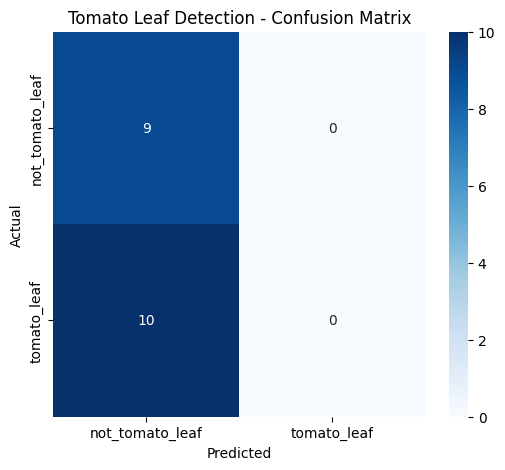

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Tomato Leaf Detection - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:


PROJECT_PATH = Path.cwd().parent

MODEL_DIR = PROJECT_PATH / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR)

Model directory: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\models


In [25]:
MODEL_PATH = MODEL_DIR / "tomato_leaf_validator.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved at:", MODEL_PATH)

Model saved successfully!
Saved at: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\models\tomato_leaf_validator.keras


In [26]:

loaded_model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
loaded_model.summary()

Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329,669 (1.26 MB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 219,780 (858.52 KB)

In [27]:
print("Class names:", class_names)

Class names: ['not_tomato_leaf', 'tomato_leaf']


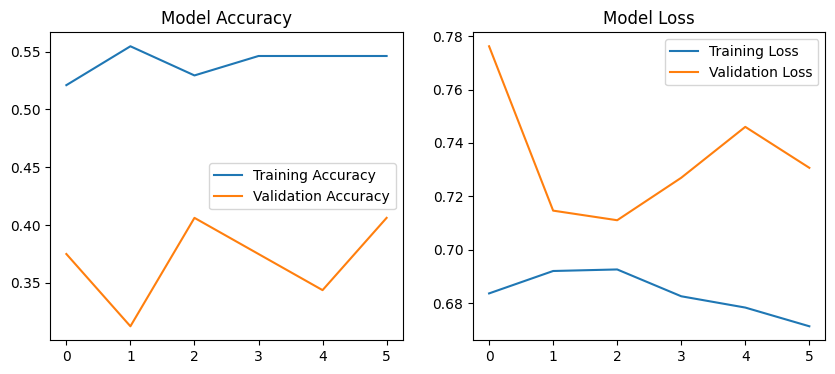

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.legend()

plt.show()

In [29]:
print("Training Accuracy:", history.history["accuracy"])
print("Validation Accuracy:", history.history["val_accuracy"])

print("Training Loss:", history.history["loss"])
print("Validation Loss:", history.history["val_loss"])


Training Accuracy: [0.5210084319114685, 0.5546218752861023, 0.529411792755127, 0.5462185144424438, 0.5462185144424438, 0.5462185144424438]
Validation Accuracy: [0.375, 0.3125, 0.40625, 0.375, 0.34375, 0.40625]
Training Loss: [0.6836466789245605, 0.6920393109321594, 0.6926167607307434, 0.6825742721557617, 0.6783444285392761, 0.6713364720344543]
Validation Loss: [0.776195764541626, 0.7146450281143188, 0.7110509872436523, 0.7269583940505981, 0.7460159659385681, 0.7306767702102661]


In [30]:
print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Final Training Loss:",
      history.history["loss"][-1])

print("Final Validation Loss:",
      history.history["val_loss"][-1])

Final Training Accuracy: 0.5462185144424438
Final Validation Accuracy: 0.40625
Final Training Loss: 0.6713364720344543
Final Validation Loss: 0.7306767702102661


In [31]:
import tensorflow as tf

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Total layers: 154


In [32]:

import tensorflow as tf

# MobileNetV2 base model
base_model.trainable = False

# Build binary classification model
inputs = tf.keras.Input(shape=(160, 160, 3))

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract image features
x = base_model(x, training=False)

# Classification layers
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

# Final model
transfer_model = tf.keras.Model(inputs, outputs)

# Compile
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [33]:

# Early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train model
history_transfer = transfer_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stop]
)



Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step - accuracy: 0.6134 - loss: 0.7081 - val_accuracy: 0.5000 - val_loss: 0.7923
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.6975 - loss: 0.5944 - val_accuracy: 0.7500 - val_loss: 0.5225
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 155ms/step - accuracy: 0.8824 - loss: 0.3890 - val_accuracy: 0.8750 - val_loss: 0.4019
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.9160 - loss: 0.3016 - val_accuracy: 0.8438 - val_loss: 0.3509
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.9076 - loss: 0.2886 - val_accuracy: 0.8750 - val_loss: 0.3707
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.9580 - loss: 0.2150 - val_accuracy: 0.9062 - val_loss: 0.3002
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.9664 - loss: 0.1828 - val_accuracy: 0.9375 - val_loss: 0.2790
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.9664 - loss: 0.1605 - val_accuracy: 0.9375 - val_loss:

In [34]:
print("Training Accuracy:", history_transfer.history["accuracy"])
print("Validation Accuracy:", history_transfer.history["val_accuracy"])
print("Training Loss:", history_transfer.history["loss"])
print("Validation Loss:", history_transfer.history["val_loss"])

Training Accuracy: [0.6134454011917114, 0.6974790096282959, 0.8823529481887817, 0.9159663915634155, 0.9075630307197571, 0.9579831957817078, 0.9663865566253662, 0.9663865566253662, 0.9495798349380493, 0.9579831957817078, 0.9579831957817078, 0.9579831957817078, 0.9747899174690247, 0.9831932783126831]
Validation Accuracy: [0.5, 0.75, 0.875, 0.84375, 0.875, 0.90625, 0.9375, 0.9375, 0.84375, 0.875, 0.96875, 0.9375, 0.9375, 0.9375]
Training Loss: [0.7081365585327148, 0.5943971276283264, 0.3889622688293457, 0.30159178376197815, 0.28860732913017273, 0.21500058472156525, 0.18281573057174683, 0.16051827371120453, 0.16317391395568848, 0.13907727599143982, 0.1426101177930832, 0.13924628496170044, 0.09522448480129242, 0.09981905668973923]
Validation Loss: [0.7922852039337158, 0.5224781036376953, 0.4018571972846985, 0.3508690297603607, 0.3706597685813904, 0.30020418763160706, 0.2790343165397644, 0.2433205395936966, 0.3258991837501526, 0.27714186906814575, 0.19531109929084778, 0.2886282801628113, 0.1

In [35]:

test_loss, test_accuracy = transfer_model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 1.0000 - loss: 0.1951
Test Loss: 0.1951383501291275
Test Accuracy: 100.0 %


In [36]:

import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = transfer_model.predict(images, verbose=0)

    predicted_labels = (predictions >= 0.5).astype(int).flatten()

    y_true.extend(labels.numpy().flatten().astype(int))
    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))


                 precision    recall  f1-score   support

not_tomato_leaf       1.00      1.00      1.00         8
    tomato_leaf       1.00      1.00      1.00        11

       accuracy                           1.00        19
      macro avg       1.00      1.00      1.00        19
   weighted avg       1.00      1.00      1.00        19



In [37]:
from pathlib import Path

PROJECT_PATH = Path.cwd().parent
MODEL_DIR = PROJECT_PATH / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "tomato_leaf_validator_mobilenetv2.keras"

transfer_model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved at:", MODEL_PATH)

Model saved successfully!
Saved at: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\models\tomato_leaf_validator_mobilenetv2.keras


In [38]:

import numpy as np

def check_class_predictions(dataset, dataset_name):
    all_labels = []
    all_probs = []

    for images, labels in dataset:
        probs = transfer_model.predict(images, verbose=0).flatten()

        all_labels.extend(labels.numpy().flatten())
        all_probs.extend(probs)

    all_labels = np.array(all_labels).astype(int)
    all_probs = np.array(all_probs)

    print("\n", dataset_name)

    for class_id, class_name in enumerate(class_names):
        class_probs = all_probs[all_labels == class_id]

        if len(class_probs) > 0:
            print(
                class_name,
                "| Images:", len(class_probs),
                "| Mean tomato probability:",
                round(float(class_probs.mean()) * 100, 2), "%"
            )

check_class_predictions(train_dataset, "TRAIN")
check_class_predictions(validation_dataset, "VALIDATION")
check_class_predictions(test_dataset, "TEST")



 TRAIN
not_tomato_leaf | Images: 65 | Mean tomato probability: 9.12 %
tomato_leaf | Images: 54 | Mean tomato probability: 92.04 %

 VALIDATION
not_tomato_leaf | Images: 13 | Mean tomato probability: 22.13 %
tomato_leaf | Images: 19 | Mean tomato probability: 84.17 %

 TEST
not_tomato_leaf | Images: 9 | Mean tomato probability: 23.75 %
tomato_leaf | Images: 10 | Mean tomato probability: 86.11 %
